# Exploratory supplement: units kept, MK exclusion, convergence re-runs, MK per-subject refit, H4 off-resonance covariate, dense checkerboard

In [1]:
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd

import figs   # figs.py, next to this notebook

# Pipeline outputs (../pipeline/run_pipeline.sh): set RR_DERIV, or edit here
DERIV = Path(os.environ.get("RR_DERIV", "/path/to/derivatives"))
A = DERIV / "analysis"
METRICS = ("FA", "MD", "MK")
SCANNERS = ["Ingenia32", "Premier48", "Premier21", "Prisma64", "Prisma32"]
pd.set_option("display.width", 220, "display.max_columns", 30, "display.max_colwidth", 60)
info = figs.pair_info(DERIV)
SHORT = {q: info[q]["repeat_scanner"].split("_")[0] for q in info}
FIGS = A / "figures" / "stage2"
FIGS.mkdir(parents=True, exist_ok=True)

## Units kept (Table S7)

Units excluded as unphysical, separately for each metric: FA ≤ 0, MD ≤ 0, MK ≤ 0 or MK > 3, in either arm, in any relevant session. Mean (range) per subject (H1), per subject–scanner pair (H2, H4) or common to all subjects (H3); % of all candidate units. Voxel-wise: one white-matter voxel in eight. ROI-wise: ROIs with at least one valid voxel.

In [2]:
counts = json.loads((A / "inputs" / "counts.json").read_text())
units, tables = counts["units"], counts["tables"]
N_ROI = 1298
rows = []
for h in ("H1", "H2", "H3", "H4"):
    for lv in "ab":
        row = {"Model": h + lv}
        for m in METRICS:
            if h == "H3":
                u = units[f"H3{lv}/common/{m}"]
                cand, kept = [u["candidates"]], [u["kept_all_subjects"]]
            elif lv == "a":
                u = [v for k, v in units.items()
                     if k.split("/")[0] == h and k.split("/")[-1] == m and "checkerboard_voxels" in v]
                cand, kept = [v["checkerboard_voxels"] for v in u], [v["checkerboard_kept"] for v in u]
            else:
                if h == "H1":
                    t = pd.read_csv(A / "inputs" / f"h1b_{m}.csv.gz", usecols=["subject", "den"])
                    kept = t[t.den == 0].groupby("subject").size().tolist()
                else:
                    kept = [v["rows"] for k, v in tables.items() if k.startswith(f"{h.lower()}b_") and k.endswith(f"_{m}")]
                cand = [N_ROI] * len(kept)
            row["Candidate units"] = f"{np.mean(cand):,.0f}" + (f" ({min(cand):,}–{max(cand):,})" if min(cand) < max(cand) else "")
            row[f"{m} kept"] = f"{np.mean(kept):,.0f} ({100 * sum(kept) / sum(cand):.1f}%)"
        rows.append(row)
pd.DataFrame(rows).set_index("Model")

,Candidate units,FA kept,MD kept,MK kept
Model,,,,
H1a,"8,125 (6,301–9,397)","7,781 (95.8%)","7,841 (96.5%)","7,230 (89.0%)"
H1b,"1,298","1,257 (96.9%)","1,259 (97.0%)","1,253 (96.6%)"
H2a,"8,376 (7,615–9,397)","7,978 (95.2%)","8,046 (96.1%)","7,303 (87.2%)"
H2b,"1,298","1,264 (97.4%)","1,266 (97.5%)","1,261 (97.1%)"
H3a,"10,050","9,163 (91.2%)","9,031 (89.9%)","2,668 (26.5%)"
H3b,"1,298","1,157 (89.1%)","1,157 (89.1%)","1,143 (88.1%)"
H4a,"8,369 (7,624–9,271)","8,294 (99.1%)","8,294 (99.1%)","7,966 (95.2%)"
H4b,"1,298","1,275 (98.2%)","1,275 (98.2%)","1,273 (98.1%)"


## MK exclusion in the voxel-wise H3 analysis (Supplementary Section 5, Figure S8)

Reads `analysis/supplementary/mk_exclusion/` (written by `../pipeline/mk_exclusion.py`).

{
 "candidates": 10050,
 "kept": 2668,
 "kept_pct": 26.547263681592035,
 "invalid_per_session_mean": 8.017676324261048,
 "invalid_per_session_min": 2.0199004975124377,
 "invalid_per_session_max": 20.64676616915423,
 "excluded_in_one_session": 1232,
 "trigger": {
  "both arms": 6047,
  "kept": 2668,
  "non-denoised only": 1290,
  "denoised only": 45
 },
 "signal_checks_only": 184
}
nondenoised: MK <= 0 in 1.87% and MK > 3 in 0.50% of WM voxel-sessions; of the values above 3, 97% exceed 10 and 95% exceed 1,000; 0.007% of voxel-sessions lie between 3 and 4; of the values <= 0, 59% are below -1
denoised: MK <= 0 in 1.39% and MK > 3 in 0.73% of WM voxel-sessions; of the values above 3, 97% exceed 10 and 97% exceed 1,000; 0.009% of voxel-sessions lie between 3 and 4; of the values <= 0, 60% are below -1
                               tract  candidates  kept_MK_pct  kept_FA_pct
                 Anterior Commissure          20          0.0        100.0
    Cingulum subsection: Peri-genual     

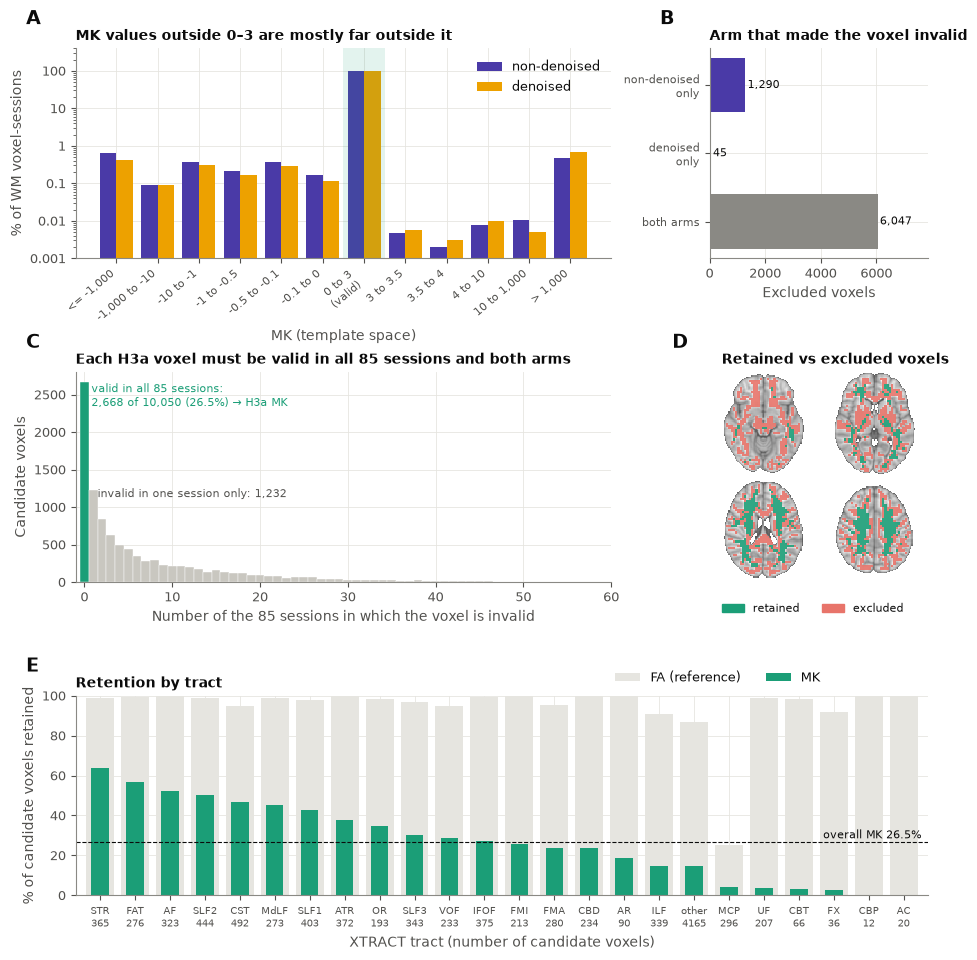

In [3]:
d = A / "supplementary" / "mk_exclusion"
S = json.loads((d / "summary.json").read_text())
out = json.loads((d / "mk_outside.json").read_text())
print(json.dumps(S, indent=1))
for arm, o in out.items():
    print(f"{arm}: MK <= 0 in {o['pct_le0']:.2f}% and MK > 3 in {o['pct_gt3']:.2f}% of WM voxel-sessions; "
          f"of the values above 3, {o['gt3_above_10_pct']:.0f}% exceed 10 and {o['gt3_above_1000_pct']:.0f}% exceed 1,000; "
          f"{o['pct_3_to_4']:.3f}% of voxel-sessions lie between 3 and 4; of the values <= 0, {o['le0_below_m1_pct']:.0f}% are below -1")
print(pd.read_csv(d / "by_tract.csv").round(1).to_string(index=False))
fig = figs.fig_mk_exclusion(DERIV)
figs.save(fig, FIGS, "FigS8_H3a_MK_exclusion")

## Fits that did not meet the convergence criteria (Tables S16a, S16b)

Table S16a: the seven ROI-wise H2 fits (H2b) that did not meet the criteria, as registered, re-run with four times as many draws (`results_extended_x4/`), and with the ROI effects $v_r$ integrated out, $\Delta_r \sim N(\alpha_0, \sigma_v^2 + \sigma_\epsilon^2)$ (`results_h2b_integrated/`, written by `../pipeline/h2b_integrated.py`; registered sampler settings). Both re-runs are exploratory.

In [4]:
def conv(rhat, ess):
    return rhat < 1.01 and ess > 1000


def h2b_runs(job):
    runs = []
    for model, d, draws in (("registered", A / "results", "2,000"), ("registered", A / "results_extended_x4", "8,000"),
                            ("v_r integrated out", A / "results_h2b_integrated", "2,000")):
        if not (d / job / "result.json").is_file():
            continue
        r = json.loads((d / job / "result.json").read_text())
        if model == "registered":
            s = pd.read_csv(d / job / "summary.csv").set_index("param").loc["alpha0"]
            m, lo, hi, rh, ess = s["mean"], s.q2_5, s.q97_5, s.rhat, s.ess_bulk
        else:
            m, lo, hi, rh, ess = r["mean_alpha0"], r["q2_5"], r["q97_5"], r["rhat_alpha0"], r["ess_alpha0"]
        runs.append(dict(draws=f"{draws} per chain (4 chains)", model=model, alpha0=f"{m:+.3f} [{lo:+.3f}, {hi:+.3f}]",
                         rhat_ess=f"{rh:.3f} / {ess:,.0f}" if model == "registered" else f"{rh:.2f} / {ess:,.0f}",
                         converged=conv(rh, ess), divergences=r["n_divergences"], alpha0_mean=m))
    return runs


jobs = sorted(p.name for p in (A / "results").glob("H2b_*"))
rows, all_rows = [], []
for job in jobs:
    _, sub, m = job.split("_")
    for r in h2b_runs(job):
        r = dict(Hypothesis=f"H2b – {m} ROI-wise", pair=SHORT[sub], **r)
        all_rows.append(r)
s16 = pd.DataFrame(all_rows)
failing = s16[(s16.model == "registered") & s16.draws.str.startswith("2,000") & ~s16.converged][["Hypothesis", "pair"]]
s16a = s16.merge(failing)
display(s16a.drop(columns=["divergences", "alpha0_mean"]))

reg = s16[(s16.model == "registered") & s16.draws.str.startswith("2,000")].set_index(["Hypothesis", "pair"])
x4 = s16[s16.draws.str.startswith("8,000")].set_index(["Hypothesis", "pair"])
integ = s16[s16.model == "v_r integrated out"].set_index(["Hypothesis", "pair"])
print(f"registered H2b: {(~reg.converged).sum()} of {len(reg)} not converged; divergences in every fit: "
      f"{reg.divergences.min():,}–{reg.divergences.max():,} of 8,000 draws")
print(f"4x draws: {x4.converged.sum()} of {len(x4)} converged; divergences {x4.divergences.min():,}–{x4.divergences.max():,} of 32,000; "
      f"max |change in alpha0| {(x4.alpha0_mean - reg.alpha0_mean.loc[x4.index]).abs().max():.3f}")
print(f"v_r integrated out: {integ.converged.sum()} of {len(integ)} converged (alpha0); divergences: "
      + ", ".join(f"{h} {p}: {v}" for (h, p), v in integ.divergences.items() if v) +
      f"; max |change in alpha0| {(integ.alpha0_mean - reg.alpha0_mean).abs().max():.3f}")
print("v_r integrated out, the fits that met the criteria as registered: bulk ESS >=",
      int(pd.Series([json.loads((A / 'results_h2b_integrated' / j / 'result.json').read_text())['ess_alpha0'] for j in jobs],
                    index=[(f"H2b – {j.split('_')[2]} ROI-wise", SHORT[j.split('_')[1]]) for j in jobs]).loc[reg.index[reg.converged]].min()))
ri = pd.read_csv(A / "results_h2b_integrated" / "results.csv")
print(f"v_r integrated out: lowest log10 BF10 {ri.log10_BF10.min():.1f}; all parameters converged in "
      f"{ri.converged_all_params.sum()} of {len(ri)}")

,Hypothesis,pair,draws,model,alpha0,rhat_ess,converged
0,H2b – MD ROI-wise,Ingenia32,"2,000 per chain (4 chains)",registered,"-0.396 [-0.453, -0.339]",1.059 / 43,False
1,H2b – MD ROI-wise,Ingenia32,"8,000 per chain (4 chains)",registered,"-0.392 [-0.449, -0.339]",1.043 / 72,False
2,H2b – MD ROI-wise,Ingenia32,"2,000 per chain (4 chains)",v_r integrated out,"-0.391 [-0.446, -0.335]","1.00 / 2,732",True
3,H2b – FA ROI-wise,Premier48,"2,000 per chain (4 chains)",registered,"-0.409 [-0.459, -0.355]",1.078 / 602,False
4,H2b – FA ROI-wise,Premier48,"8,000 per chain (4 chains)",registered,"-0.412 [-0.462, -0.356]",1.041 / 80,False
5,H2b – FA ROI-wise,Premier48,"2,000 per chain (4 chains)",v_r integrated out,"-0.408 [-0.460, -0.353]","1.00 / 2,643",True
6,H2b – MK ROI-wise,Premier48,"2,000 per chain (4 chains)",registered,"+0.573 [+0.519, +0.629]",1.008 / 752,False
7,H2b – MK ROI-wise,Premier48,"8,000 per chain (4 chains)",registered,"+0.575 [+0.521, +0.629]","1.002 / 2,299",True
8,H2b – MK ROI-wise,Premier48,"2,000 per chain (4 chains)",v_r integrated out,"+0.576 [+0.520, +0.630]","1.00 / 2,757",True
9,H2b – FA ROI-wise,Prisma64,"2,000 per chain (4 chains)",registered,"+0.636 [+0.582, +0.689]",1.011 / 833,False


registered H2b: 7 of 15 not converged; divergences in every fit: 162–2,623 of 8,000 draws
4x draws: 3 of 7 converged; divergences 2,769–15,216 of 32,000; max |change in alpha0| 0.004
v_r integrated out: 15 of 15 converged (alpha0); divergences: H2b – MD ROI-wise Premier21: 5; max |change in alpha0| 0.005
v_r integrated out, the fits that met the criteria as registered: bulk ESS >= 2369
v_r integrated out: lowest log10 BF10 32.2; all parameters converged in 14 of 15


Table S16b: the voxel-wise H3 fits (H3a) that did not meet the criteria, as registered and with four times as many draws. Each H3a test is two fits, one per arm; the R-hat / bulk ESS shown is that of the inferential parameter that failed.

In [5]:
INFER = ["sd_u", "sd_w", "sigma_cond[0]"]
ARM = {"den0": "non-denoised", "den1": "denoised"}


def icc_ci(d, m, den):
    x = np.load(d / f"H3a_{m}_{den}" / "icc_draws.npz")["icc"]
    return f"{x.mean():.3f} [{np.quantile(x, 0.025):.3f}, {np.quantile(x, 0.975):.3f}]"


reg_conv = pd.read_csv(A / "results" / "convergence_all.csv")
rows = []
for m in METRICS:
    c = reg_conv[reg_conv.job.str.startswith(f"H3a_{m}_") & reg_conv.param.isin(INFER)]
    bad = c[(c.rhat >= 1.01) | (c.ess_bulk <= 1000)]
    if bad.empty:
        continue
    job, par = bad.sort_values("ess_bulk").iloc[0][["job", "param"]]
    for d, draws in ((A / "results", "2,000"), (A / "results_extended_x4", "8,000")):
        r = json.loads((d / f"H3a_{m}_delta_icc.json").read_text())
        cv = pd.read_csv(d / "convergence_all.csv").set_index(["job", "param"])
        rows.append({"Hypothesis": f"H3a – {m} voxel-wise", "Draws": f"{draws} per chain (4 chains)",
                     "ICC non-denoised": icc_ci(d, m, "den0"), "ICC denoised": icc_ci(d, m, "den1"),
                     "ΔICC [95% CrI]": f"{r['mean_delta']:+.3f} [{r['q2_5']:+.3f}, {r['q97_5']:+.3f}]",
                     "P(ΔICC > 0)": f"{r['p_delta_gt0']:.3f}",
                     "Failing parameter": f"{par.replace('sd_u', 'σu')} ({ARM[job.split('_')[-1]]})",
                     "R-hat / ESS": f"{cv.loc[(job, par), 'rhat']:.3f} / {cv.loc[(job, par), 'ess_bulk']:,.0f}",
                     "all inferential parameters converged": bool(r["converged"]),
                     "divergences": int(r.get("n_divergences", 0))})
display(pd.DataFrame(rows))

,Hypothesis,Draws,ICC non-denoised,ICC denoised,ΔICC [95% CrI],P(ΔICC > 0),Failing parameter,R-hat / ESS,all inferential parameters converged,divergences
0,H3a – MD voxel-wise,"2,000 per chain (4 chains)","0.034 [0.013, 0.084]","0.034 [0.013, 0.088]","+0.000 [-0.055, +0.059]",0.503,σu (denoised),1.004 / 931,False,0
1,H3a – MD voxel-wise,"8,000 per chain (4 chains)","0.034 [0.013, 0.083]","0.034 [0.013, 0.086]","-0.000 [-0.055, +0.057]",0.496,σu (denoised),"1.000 / 3,887",True,0
2,H3a – MK voxel-wise,"2,000 per chain (4 chains)","0.073 [0.029, 0.163]","0.126 [0.052, 0.278]","+0.052 [-0.064, +0.217]",0.809,σu (non-denoised),1.002 / 963,False,0
3,H3a – MK voxel-wise,"8,000 per chain (4 chains)","0.072 [0.028, 0.169]","0.127 [0.053, 0.280]","+0.055 [-0.066, +0.217]",0.823,σu (non-denoised),"1.001 / 4,187",True,0


## Voxel-wise H3 of MK with validity required only within each subject (Table S17)

Registered model: the registered H3 model fitted to the per-subject voxel set (`inputs_h3a_mk_persubject/`, written by `../pipeline/h3a_mk_persubject.py`; fits in `results_h3a_mk_persubject/` with 2,000 draws per chain and `results_h3a_mk_persubject_x4/` with 8,000), next to the registered voxel set with 8,000 draws (`results_extended_x4/`). Per-voxel ICC(2,1): as in Figure 8 (`H3.ipynb`), from the subjects with complete data for each voxel; for the per-subject set, voxels with at least 8 of the 10 subjects.

In [6]:
import warnings


def model_row(name, d, voxels):
    r = json.loads((d / "H3a_MK_delta_icc.json").read_text())
    cv = pd.read_csv(d / "convergence_all.csv")
    cv = cv[cv.job.str.startswith("H3a_MK_") & cv.param.isin(INFER)].sort_values("ess_bulk").iloc[0]
    return {"Analysis": "Registered model", "Voxel set": name, "Voxels": voxels,
            "ICC non-denoised": icc_ci(d, "MK", "den0"), "ICC denoised": icc_ci(d, "MK", "den1"),
            "ΔICC": f"{r['mean_delta']:+.3f} [{r['q2_5']:+.3f}, {r['q97_5']:+.3f}]", "P(ΔICC > 0)": f"{r['p_delta_gt0']:.3f}",
            "Voxels with ΔICC > 0": "–", "R-hat / ESS": f"{cv.rhat:.3f} / {cv.ess_bulk:,.0f} ({cv.param}, {cv.job[-4:]})",
            "converged": bool(r["converged"])}


def cube(path):
    """(2 arms, units, subjects, scanners) from an H3 input table; NaN where a subject does not contribute a unit."""
    t = pd.read_csv(path, usecols=["subject", "scanner", "unit", "den", "y_raw"])
    u, s, c = (np.sort(t[k].unique()) for k in ("unit", "subject", "scanner"))
    y = np.full((2, u.size, s.size, c.size), np.nan)
    y[t.den, np.searchsorted(u, t.unit), np.searchsorted(s, t.subject), np.searchsorted(c, t.scanner)] = t.y_raw
    return y


def icc21_rows(x):
    """ICC(2,1) per unit on the complete subject rows only (as in H3.ipynb). x: (units, n, k)."""
    k = x.shape[2]
    ok = np.isfinite(x).all(axis=2)
    n = ok.sum(axis=1).astype(float)
    x = np.where(ok[..., None], x, np.nan)
    with warnings.catch_warnings(), np.errstate(invalid="ignore", divide="ignore"):
        warnings.simplefilter("ignore", RuntimeWarning)
        g = np.nanmean(x, axis=(1, 2), keepdims=True)
        rm, cm = np.nanmean(x, axis=2, keepdims=True), np.nanmean(x, axis=1, keepdims=True)
        msr = k * np.nansum((rm - g) ** 2, axis=(1, 2)) / (n - 1)
        msc = n * np.nansum((cm - g) ** 2, axis=(1, 2)) / (k - 1)
        mse = np.nansum((x - rm - cm + g) ** 2, axis=(1, 2)) / ((n - 1) * (k - 1))
        return (msr - mse) / (msr + (k - 1) * mse + k * (msc - mse) / n), n


def icc_row(name, path, min_sub):
    y = cube(path)
    i0, n = icc21_rows(y[0])
    i1, _ = icc21_rows(y[1])
    sel = n >= min_sub
    dd = i1[sel] - i0[sel]
    return {"Analysis": "Per-voxel ICC(2,1)", "Voxel set": name, "Voxels": f"{sel.sum():,}",
            "ICC non-denoised": f"{np.median(i0[sel]):.3f}", "ICC denoised": f"{np.median(i1[sel]):.3f}",
            "ΔICC": f"{np.median(dd):+.3f}", "P(ΔICC > 0)": "–", "Voxels with ΔICC > 0": f"{100 * (dd > 0).mean():.1f}%",
            "R-hat / ESS": "–"}


ps = json.loads((A / "inputs_h3a_mk_persubject" / "counts.json").read_text())
pct = ps["kept_per_subject_pct"].values()
tab = [model_row("Registered", A / "results_extended_x4", "2,668"),
       model_row("Per subject", A / "results_h3a_mk_persubject_x4", f"{ps['units_in_any_subject']:,} ({min(pct):.0f}–{max(pct):.0f}% per subject)"),
       icc_row("Registered", A / "inputs" / "h3a_MK.csv.gz", 10),
       icc_row("Per subject (≥ 8 subjects)", A / "inputs_h3a_mk_persubject" / "h3a_MK.csv.gz", 8)]
display(pd.DataFrame(tab))
print("per-subject set, all voxels with at least 3 subjects:", icc_row("all", A / "inputs_h3a_mk_persubject" / "h3a_MK.csv.gz", 3))
print("per-subject fit with 2,000 draws:", model_row("Per subject, 2,000 draws", A / "results_h3a_mk_persubject", "")["R-hat / ESS"],
      "| converged:", model_row("", A / "results_h3a_mk_persubject", "")["converged"])
print("subjects per voxel:", ps["units_by_n_subjects"])

,Analysis,Voxel set,Voxels,ICC non-denoised,ICC denoised,ΔICC,P(ΔICC > 0),Voxels with ΔICC > 0,R-hat / ESS,converged
0,Registered model,Registered,"2,668","0.072 [0.028, 0.169]","0.127 [0.053, 0.280]","+0.055 [-0.066, +0.217]",0.823,–,"1.001 / 4,187 (sd_u, den0)",True
1,Registered model,Per subject,"9,729 (62–77% per subject)","0.041 [0.016, 0.100]","0.066 [0.026, 0.160]","+0.025 [-0.048, +0.124]",0.773,–,"1.001 / 3,523 (sd_u, den1)",True
2,"Per-voxel ICC(2,1)",Registered,"2,668",0.280,0.488,+0.185,–,92.4%,–,NaN
3,"Per-voxel ICC(2,1)",Per subject (≥ 8 subjects),"5,244",0.293,0.474,+0.145,–,87.0%,–,NaN


per-subject set, all voxels with at least 3 subjects: {'Analysis': 'Per-voxel ICC(2,1)', 'Voxel set': 'all', 'Voxels': '8,823', 'ICC non-denoised': '0.293', 'ICC denoised': '0.445', 'ΔICC': '+0.113', 'P(ΔICC > 0)': '–', 'Voxels with ΔICC > 0': '80.5%', 'R-hat / ESS': '–'}
per-subject fit with 2,000 draws: 1.002 / 837 (sd_u, den1) | converged: False
subjects per voxel: {'1': 396, '2': 510, '3': 595, '4': 638, '5': 693, '6': 769, '7': 884, '8': 1112, '9': 1464, '10': 2668}


## H4 with z-scored |off-resonance| (Table S19)

Registered fits: |off-resonance| in Hz. Exploratory: |off-resonance| z-scored within pair. β1 is shown per SD of the covariate.

In [7]:
VAR = {"|off| Hz (main)": ("results", "off_hz"), "|off| z-scored": ("results_h4_abs_z", "off_z")}
info = figs.pair_info(DERIV)


def verdict(b1, bf):
    if bf < 0.1:
        return "null"
    return "inconclusive" if bf <= 10 else "supports H4" if b1 > 0 else "opposite"


rows = []
for lv, level in (("a", "voxel"), ("b", "ROI")):
    for m in METRICS:
        for q in info:
            tab = pd.read_csv(A / "inputs" / f"h4{lv}_{q}_{m}.csv.gz", usecols=["off_hz", "off_z"])
            for name, (d, col) in VAR.items():
                r = json.loads((A / d / f"H4{lv}_{q}_{m}" / "result.json").read_text())
                rows.append(dict(covariate=name, Hypothesis=figs.hyp_label("H4", level, m), level=level, metric=m, pair=q,
                                 scanner=info[q]["repeat_scanner"].split("_")[0], beta1_sd=r["mean_beta1"] * tab[col].std(ddof=0),
                                 BF10=r["BF10"], verdict=verdict(r["mean_beta1"], r["BF10"]), converged=r["converged"]))
h4 = pd.DataFrame(rows)
print("all fits converged:", bool(h4.converged.all()))
n = h4.groupby(["covariate", "verdict"], sort=False).size().unstack(fill_value=0)[["supports H4", "null", "opposite", "inconclusive"]]
main = h4[h4.covariate == "|off| Hz (main)"].set_index(["level", "metric", "pair"]).verdict
n["same verdict as main"] = [int((g.set_index(["level", "metric", "pair"]).verdict == main).sum())
                             for _, g in h4.groupby("covariate", sort=False)]
s4 = main[main == "supports H4"].index
n["of the tests supporting H4 (main), still supporting"] = [
    int((g.set_index(["level", "metric", "pair"]).verdict.loc[s4] == "supports H4").sum()) for _, g in h4.groupby("covariate", sort=False)]
n

all fits converged: True


verdict,supports H4,null,opposite,inconclusive,same verdict as main,"of the tests supporting H4 (main), still supporting"
covariate,,,,,,
|off| Hz (main),5,11,12,2,30,5
|off| z-scored,5,10,12,3,29,5


In [8]:
h4["cell"] = [f"{b:+.3f}, BF {'>100' if bf > 100 else f'{bf:.2g}'} ({v})" for b, bf, v in zip(h4.beta1_sd, h4.BF10, h4.verdict)]
for name in VAR:
    print(name)
    print(h4[h4.covariate == name].pivot(index="Hypothesis", columns="scanner", values="cell")[SCANNERS].to_string(), "\n")

|off| Hz (main)
scanner                                   Ingenia32                       Premier48                   Premier21                    Prisma64                    Prisma32
Hypothesis                                                                                                                                                             
H4a – FA voxel-wise     +0.027, BF 27 (supports H4)       +0.005, BF 0.00052 (null)     -0.012, BF 0.002 (null)   -0.003, BF 0.00046 (null)   -0.006, BF 0.00061 (null)
H4a – MD voxel-wise         +0.010, BF 0.048 (null)      -0.041, BF >100 (opposite)  -0.037, BF >100 (opposite)  -0.018, BF >100 (opposite)  -0.017, BF >100 (opposite)
H4a – MK voxel-wise   +0.047, BF >100 (supports H4)      -0.074, BF >100 (opposite)  -0.158, BF >100 (opposite)  -0.088, BF >100 (opposite)  -0.121, BF >100 (opposite)
H4b – FA ROI-wise     +0.063, BF >100 (supports H4)     +0.040, BF 12 (supports H4)   +0.004, BF 0.00056 (null)   -0.005, BF 0.00058 (null)    -

In [9]:
w = h4.copy()
w["v"] = w.verdict.replace({"supports H4": "H4"})
w = w.pivot(index=["Hypothesis", "scanner"], columns="covariate", values="v")
w["cell"] = w["|off| Hz (main)"] + " / " + w["|off| z-scored"]
w.cell.unstack("scanner")[SCANNERS]

scanner,Ingenia32,Premier48,Premier21,Prisma64,Prisma32
Hypothesis,,,,,
H4a – FA voxel-wise,H4 / H4,null / null,null / null,null / null,null / null
H4a – MD voxel-wise,null / inconclusive,opposite / opposite,opposite / opposite,opposite / opposite,opposite / opposite
H4a – MK voxel-wise,H4 / H4,opposite / opposite,opposite / opposite,opposite / opposite,opposite / opposite
H4b – FA ROI-wise,H4 / H4,H4 / H4,null / null,null / null,null / null
H4b – MD ROI-wise,H4 / H4,opposite / opposite,null / null,null / null,null / null
H4b – MK ROI-wise,inconclusive / inconclusive,inconclusive / inconclusive,opposite / opposite,opposite / opposite,opposite / opposite


## Dense checkerboard (Table S20)

The voxel-wise models with one white-matter voxel in eight (main analysis) and with the dense checkerboard (about half of the voxels). β1: ×10⁻³ per Hz. BF10; for H3a, P(ΔICC > 0). † did not meet the convergence criteria.

In [10]:
RES = {"1 in 8": A / "results", "dense": A / "results_dense"}
RULE = {"H1": lambda b: b < 0, "H2": lambda b: True, "H4": lambda b: b > 0}
YES = {"H1": "supports H1", "H2": "denoising changes bias", "H4": "H4"}


def bf_text(x):
    return ">100" if x > 100 else f"{x:.1f}" if x >= 1 else f"{x:.3f}" if x >= 0.001 else "<0.001"


def fit_cells(run, d, job, h, target):
    r = json.loads((d / job / "result.json").read_text())
    s = pd.read_csv(d / job / "summary.csv").set_index("param").loc[target]
    k, q = (1e3, 2) if h == "H4" else (1, 3)
    est = f"{k * s['mean']:+.{q}f} [{k * s.q2_5:+.{q}f}, {k * s.q97_5:+.{q}f}]" + ("" if r["converged"] else " †")
    b, bf = r[f"mean_{target}"], r["BF10"]
    v = "null" if bf < 0.1 else "inconclusive" if bf <= 10 else YES[h] if RULE[h](b) else "opposite"
    return {f"{run}: estimate [95% CrI]": est, f"{run}: BF10 or P": bf_text(bf), f"{run}: verdict": v}


def icc_cells(run, d, m):
    r = json.loads((d / f"H3a_{m}_delta_icc.json").read_text())
    p = r["p_delta_gt0"]
    est = f"{r['mean_delta']:+.3f} [{r['q2_5']:+.3f}, {r['q97_5']:+.3f}]" + ("" if r["converged"] else " †")
    return {f"{run}: estimate [95% CrI]": est, f"{run}: BF10 or P": f"{p:.2f}",
            f"{run}: verdict": "supports H3" if p > 0.95 else "null" if p < 0.05 else "inconclusive"}


order = sorted(info, key=lambda q: SCANNERS.index(info[q]["repeat_scanner"].split("_")[0]))
rows = []
for h, target in (("H1", "alpha1"), ("H2", "alpha0"), ("H3", None), ("H4", "beta1")):
    for m in METRICS:
        for q in (order if h in ("H2", "H4") else [None]):
            row = {"Test": f"{h}a {m}", "Pair": info[q]["repeat_scanner"].split("_")[0] if q else "–"}
            for run, d in RES.items():
                row.update(icc_cells(run, d, m) if h == "H3" else
                           fit_cells(run, d, f"{h}a_{q}_{m}" if q else f"{h}a_{m}", h, target))
            rows.append(row)
s18 = pd.DataFrame(rows)
same = s18["1 in 8: verdict"] == s18["dense: verdict"]
print(f"same verdict: {same.sum()} of {len(s18)}; different: "
      + "; ".join(f"{t} {p}" for t, p in s18.loc[~same, ["Test", "Pair"]].values))
with pd.option_context("display.max_rows", None):
    display(s18)

same verdict: 35 of 36; different: H4a MD Ingenia32


,Test,Pair,1 in 8: estimate [95% CrI],1 in 8: BF10 or P,1 in 8: verdict,dense: estimate [95% CrI],dense: BF10 or P,dense: verdict
0,H1a FA,–,"-0.036 [-0.046, -0.026]",>100,supports H1,"-0.038 [-0.043, -0.033]",>100,supports H1
1,H1a MD,–,"-0.074 [-0.084, -0.064]",>100,supports H1,"-0.075 [-0.079, -0.070]",>100,supports H1
2,H1a MK,–,"-0.425 [-0.436, -0.415]",>100,supports H1,"-0.424 [-0.428, -0.419]",>100,supports H1
3,H2a FA,Ingenia32,"-0.513 [-0.536, -0.491]",>100,denoising changes bias,"-0.515 [-0.526, -0.503]",>100,denoising changes bias
4,H2a FA,Premier48,"-0.161 [-0.184, -0.138]",>100,denoising changes bias,"-0.161 [-0.172, -0.150]",>100,denoising changes bias
5,H2a FA,Premier21,"-0.333 [-0.355, -0.311]",>100,denoising changes bias,"-0.315 [-0.326, -0.304]",>100,denoising changes bias
6,H2a FA,Prisma64,"+0.287 [+0.264, +0.310]",>100,denoising changes bias,"+0.292 [+0.281, +0.304]",>100,denoising changes bias
7,H2a FA,Prisma32,"+0.429 [+0.408, +0.450]",>100,denoising changes bias,"+0.450 [+0.439, +0.460]",>100,denoising changes bias
8,H2a MD,Ingenia32,"-0.199 [-0.221, -0.176]",>100,denoising changes bias,"-0.196 [-0.207, -0.185]",>100,denoising changes bias
9,H2a MD,Premier48,"-0.147 [-0.169, -0.124]",>100,denoising changes bias,"-0.150 [-0.162, -0.139]",>100,denoising changes bias
